## 1. Download and import Dataset and libraries

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("aravindram11/funsdform-understanding-noisy-scanned-documents")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'funsdform-understanding-noisy-scanned-documents' dataset.
Path to dataset files: /kaggle/input/funsdform-understanding-noisy-scanned-documents


### 2. Khám phá cấu trúc thư mục dữ liệu
Kiểm tra xem thư mục tải về chứa những tệp và thư mục con nào.

In [ ]:
import os

def list_files(startpath):
    for root, dirs, files in os.walk(startpath):
        level = root.replace(startpath, '').count(os.sep)
        indent = ' ' * 4 * (level)
        print('{}{}/'.format(indent, os.path.basename(root)))
        subindent = ' ' * 4 * (level + 1)
        for f in files:
            print('{}{}'.format(subindent, f))

print(f"Khám phá thư mục: {path}")
list_files(path)


Khám phá thư mục: /kaggle/input/funsdform-understanding-noisy-scanned-documents
funsdform-understanding-noisy-scanned-documents/
    dataset/
        training_data/
            annotations/
                0060036622.json
                12052385.json
                12825369.json
                71563825.json
                0011906503.json
                91914407.json
                0012529284.json
                91581919.json
                00837285.json
                91391310.json
                0013255595.json
                0011845203.json
                0060024314.json
                89368010.json
                00920294.json
                93380187.json
                00040534.json
                89386032.json
                82254638.json
                00851772_1780.json
                89817999_8002.json
                00283813.json
                91315069_91315070.json
                00860012_00860014.json
                00836244.json
                0060

### 3. Trực quan hóa dữ liệu mẫu
Đọc một tệp hình ảnh và tệp JSON tương ứng để hiển thị các bounding boxes và nhãn của chúng (Question, Answer, Header, Other).

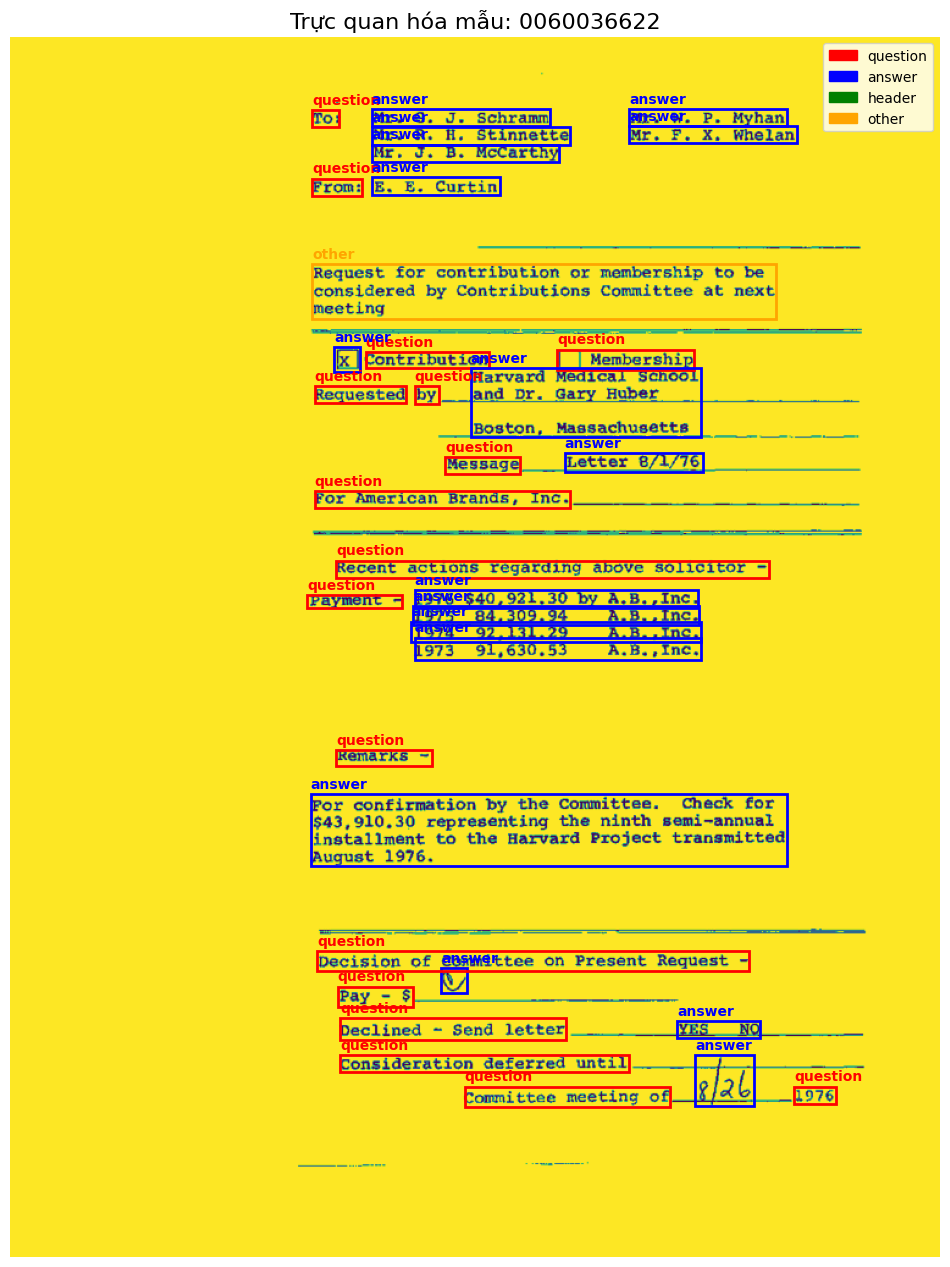

In [ ]:
import json
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

# Lấy một mẫu từ tập huấn luyện (ID: 0060036622)
sample_id = "0060036622"
image_path = f"{path}/dataset/training_data/images/{sample_id}.png"
json_path = f"{path}/dataset/training_data/annotations/{sample_id}.json"

# Đọc và hiển thị hình ảnh
img = Image.open(image_path)
fig, ax = plt.subplots(figsize=(12, 16))
ax.imshow(img)

# Đọc dữ liệu chú thích (annotations)
with open(json_path, 'r', encoding='utf-8') as f:
    data = json.load(f)

# Định nghĩa màu sắc cho các nhãn khác nhau
color_map = {
    'question': 'red',
    'answer': 'blue',
    'header': 'green',
    'other': 'orange'
}

# Vẽ bounding boxes lên hình ảnh
for form_item in data['form']:
    box = form_item['box']
    label = form_item['label']

    # box trong FUNSD có định dạng [x_left, y_top, x_right, y_bottom]
    x = box[0]
    y = box[1]
    w = box[2] - box[0]
    h = box[3] - box[1]

    color = color_map.get(label, 'black')

    # Thêm hình chữ nhật
    rect = patches.Rectangle((x, y), w, h, linewidth=2, edgecolor=color, facecolor='none')
    ax.add_patch(rect)

    # Tùy chọn: Thêm text label nhỏ ở góc
    ax.text(x, y - 5, label, color=color, fontsize=10, weight='bold')

# Thêm chú thích cho biểu đồ
handles = [patches.Patch(color=color, label=label) for label, color in color_map.items()]
plt.legend(handles=handles, loc='upper right')
plt.title(f"Trực quan hóa mẫu: {sample_id}", fontsize=16)
plt.axis('off')
plt.show()

### 4. Thống kê phân bố nhãn (Label Distribution)
Phân tích toàn bộ tập dữ liệu huấn luyện để kiểm tra số lượng các nhãn và xem có sự mất cân bằng lớp (class imbalance) hay không.

Tổng số hình ảnh trong tập huấn luyện: 149

Phân bố các nhãn:
 - Question: 3266
 - Answer: 2802
 - Other: 902
 - Header: 441


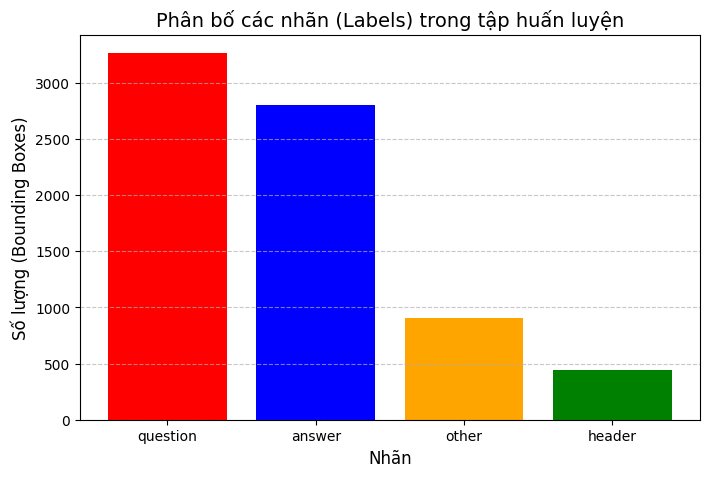

In [ ]:
import glob
from collections import Counter

# Lấy đường dẫn tất cả các tệp JSON trong tập huấn luyện
train_json_files = glob.glob(f"{path}/dataset/training_data/annotations/*.json")
print(f"Tổng số hình ảnh trong tập huấn luyện: {len(train_json_files)}")

label_counts = Counter()

# Duyệt qua từng tệp để đếm số lượng các nhãn
for json_file in train_json_files:
    with open(json_file, 'r', encoding='utf-8') as f:
        data = json.load(f)
        for item in data['form']:
            label_counts[item['label']] += 1

print("\nPhân bố các nhãn:")
for label, count in label_counts.most_common():
    print(f" - {label.capitalize()}: {count}")

# Trực quan hóa bằng biểu đồ cột
plt.figure(figsize=(8, 5))
labels = list(label_counts.keys())
counts = list(label_counts.values())

# Ánh xạ màu tương tự như trước để nhất quán
bar_colors = [color_map.get(label, 'grey') for label in labels]

plt.bar(labels, counts, color=bar_colors)
plt.title('Phân bố các nhãn (Labels) trong tập huấn luyện', fontsize=14)
plt.xlabel('Nhãn', fontsize=12)
plt.ylabel('Số lượng (Bounding Boxes)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### 5. Tiền xử lý dữ liệu (Data Preprocessing)
Trích xuất các từ (words), tọa độ (bounding boxes), nhãn (labels) từ tập dữ liệu và chuẩn hóa tọa độ bounding box về khoảng 0-1000.

In [ ]:
import pandas as pd
import os
from PIL import Image
from tqdm import tqdm

# Hàm chuẩn hóa tọa độ hộp giới hạn (bounding box) về tỷ lệ 0-1000
def normalize_box(box, width, height):
    return [
        int(1000 * (box[0] / width)),
        int(1000 * (box[1] / height)),
        int(1000 * (box[2] / width)),
        int(1000 * (box[3] / height))
    ]

def load_funsd_data(data_path):
    dataset = []
    json_files = glob.glob(f"{data_path}/annotations/*.json")

    for json_path in tqdm(json_files, desc=f"Đang xử lý dữ liệu từ {os.path.basename(data_path)}"):
        file_id = os.path.basename(json_path).split('.')[0]
        image_path = f"{data_path}/images/{file_id}.png"

        # Lấy kích thước hình ảnh để chuẩn hóa bounding box
        try:
            with Image.open(image_path) as img:
                width, height = img.size
        except Exception as e:
            print(f"Lỗi đọc ảnh {image_path}: {e}")
            continue

        with open(json_path, 'r', encoding='utf-8') as f:
            data = json.load(f)

        words = []
        boxes = []
        labels = []

        # Bóc tách từng từ (word) trong các item
        for item in data['form']:
            for word_info in item['words']:
                text = word_info['text']
                if not text.strip(): # Bỏ qua các chuỗi rỗng
                    continue

                words.append(text)
                boxes.append(normalize_box(word_info['box'], width, height))
                labels.append(item['label'])

        dataset.append({
            'id': file_id,
            'image_path': image_path,
            'words': words,
            'bboxes': boxes,
            'labels': labels
        })

    return pd.DataFrame(dataset)

# Áp dụng cho tập huấn luyện
train_data_path = f"{path}/dataset/training_data"
df_train = load_funsd_data(train_data_path)

print(f"\nĐã tiền xử lý thành công {len(df_train)} tài liệu huấn luyện.")
display(df_train.head())

Đang xử lý dữ liệu từ training_data: 100%|██████████| 149/149 [00:00<00:00, 740.52it/s]


Đã tiền xử lý thành công 149 tài liệu huấn luyện.


,id,image_path,words,bboxes,labels
0,0060036622,/kaggle/input/funsdform-understanding-noisy-sc...,"[TO:, From:, Contribution, Requested, by, 1976...","[[324, 60, 353, 74], [324, 116, 377, 130], [38...","[question, question, question, question, quest..."
1,12052385,/kaggle/input/funsdform-understanding-noisy-sc...,"[KOOL, DESCRIPTION:, SUPPLIER:, CUMULATIVE, JA...","[[69, 41, 129, 54], [69, 107, 200, 126], [69, ...","[question, question, question, question, answe..."
2,12825369,/kaggle/input/funsdform-understanding-noisy-sc...,"[MARKET, POPULATION, OPERATOR, BRAND, SCHEDULE...","[[77, 135, 139, 149], [77, 165, 165, 179], [73...","[question, question, question, question, quest..."
3,71563825,/kaggle/input/funsdform-understanding-noisy-sc...,"[Date:, Market(s):, Male:, Female:, Bogotá:, M...","[[687, 205, 729, 219], [156, 388, 236, 403], [...","[question, question, question, question, quest..."
4,0011906503,/kaggle/input/funsdform-understanding-noisy-sc...,"[0465E, ($000), Title, Purpose, 1, 2, 3, 4, 7,...","[[822, 51, 874, 65], [443, 126, 497, 142], [64...","[other, other, question, header, question, que..."


### 6. Xử lý tập kiểm tra (Test Data) và Mã hóa (Tokenization)
Áp dụng tiền xử lý cho tập kiểm tra và khởi tạo Tokenizer từ mô hình LayoutLM để chuẩn bị dữ liệu đầu vào cho mạng nơ-ron.

In [ ]:
# Xử lý tập kiểm tra
test_data_path = f"{path}/dataset/testing_data"
df_test = load_funsd_data(test_data_path)

print(f"\nĐã tiền xử lý thành công {len(df_test)} tài liệu kiểm tra.")


Đang xử lý dữ liệu từ testing_data: 100%|██████████| 50/50 [00:00<00:00, 605.76it/s]


Đã tiền xử lý thành công 50 tài liệu kiểm tra.


In [ ]:
import torch
from transformers import LayoutLMTokenizerFast

# Khởi tạo tokenizer từ mô hình pre-trained LayoutLM
tokenizer = LayoutLMTokenizerFast.from_pretrained("microsoft/layoutlm-base-uncased")

# Lấy thử mẫu đầu tiên trong tập huấn luyện để xem tokenizer hoạt động như thế nào
sample_words = df_train.iloc[0]['words']
sample_boxes = df_train.iloc[0]['bboxes']

# Mã hóa mẫu đầu tiên (bỏ tham số boxes vì tokenizer v1 không tự xử lý)
encoding = tokenizer(
    sample_words,
    is_split_into_words=True,
    padding="max_length",
    truncation=True,
    max_length=512,
    return_tensors="pt"
)

# Tự căn chỉnh (align) bounding boxes với các sub-tokens bằng word_ids
word_ids = encoding.word_ids(batch_index=0)
token_boxes = []

for word_idx in word_ids:
    if word_idx is None:
        # Các token đặc biệt ([CLS], [SEP], [PAD]) được gán box [0, 0, 0, 0]
        token_boxes.append([0, 0, 0, 0])
    else:
        # Lấy box của từ gốc cho các sub-tokens tương ứng
        token_boxes.append(sample_boxes[word_idx])

# Gán mảng token_boxes vào dictionary encoding
encoding['bbox'] = torch.tensor([token_boxes])

print("Các keys trong kết quả mã hóa:", encoding.keys())
print("\nKích thước của input_ids (mã định danh từ):", encoding['input_ids'].shape)
print("Kích thước của bbox (tọa độ):", encoding['bbox'].shape)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/606 [00:00<?, ?B/s]

Các keys trong kết quả mã hóa: KeysView({'input_ids': tensor([[  101,  2000,  1024,  2013,  1024,  6691,  7303,  2011,  3299,   100,
          4471,  2720,  1012,  1043,  1012,  1046,  1012,  8040, 13492,  7382,
          2720,  1012,  1059,  1012,  1052,  1012,  2026,  4819,  2720,  1012,
          1042,  1012,  1060,  1012,  1059, 16001,  2319,  2720,  1012,  1054,
          1012,  1044,  1012,  2358, 23111,  7585,  2720,  1012,  1046,  1012,
          1038,  1012, 12584,  1041,  1012,  1041,  1012, 20099,  2378,  5227,
          2005,  6691,  2030,  5779,  2000,  2022,  2641,  2011,  5857,  2837,
          2012,  2279,  3116,   100,  5779,  5765,  2966,  2082,  1998,  2852,
          1012,  5639,  9594,  2121,  3731,  1010,  4404,  3661,  1022,  1013,
          1015,  1013,  6146,  2005,  2137,  9639,  1010,  4297,  1012,  3522,
          4506,  4953,  2682, 15468,  3299,  1002,  2871,  1010,  6227,  2487,
          1012,  2382,  2011,  1037,  1012,  1038,  1012,  1010,  4297,  1012

### 7. Chuyển đổi sang Qwen2.5-VL cho SFT và Đánh giá (VQA, IE)
Phần này thiết lập môi trường để Fine-tune mô hình Qwen2.5-VL (3B) sử dụng kỹ thuật LoRA. Kỹ thuật này giúp bạn train mô hình lớn trên GPU có bộ nhớ hạn chế (như Colab T4/L4).

In [ ]:
!pip install -q -U \
    "transformers==4.57.1" \
    "peft==0.17.1" \
    "accelerate>=1.2" \
    "qwen-vl-utils[decord]" \
    "Pillow>=11.0" \
    datasets

print("✅ Installation completed.")

✅ Installation completed.


In [ ]:
import torch
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from transformers import (
    AutoProcessor,
    Qwen2_5_VLForConditionalGeneration,
)

model_id = "Qwen/Qwen2.5-VL-3B-Instruct"

# 1. Processor
processor = AutoProcessor.from_pretrained(model_id)

# 2. Model
model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    model_id,
    torch_dtype=torch.bfloat16,
    device_map="auto",
)

# 3. LoRA
lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj",
        "gate_proj",
        "up_proj",
        "down_proj",
    ],
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
)

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

print("Qwen2.5-VL + LoRA loaded successfully!")

preprocessor_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

The image processor of type `Qwen2VLImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. Note that this behavior will be extended to all models in a future release.


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

...

model-00001-of-00002.safetensors:   0%|          | 0.00/3.98G [00:00<?, ?B/s]

model-00002-of-00002.safetensors:   0%|          | 0.00/3.53G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/216 [00:00<?, ?B/s]

trainable params: 37,152,768 || all params: 3,791,775,744 || trainable%: 0.9798
Qwen2.5-VL + LoRA loaded successfully!


#### 7.1 Chuẩn bị dữ liệu định dạng Chat cho SFT
Qwen-VL yêu cầu đầu vào dạng tin nhắn hội thoại chứa thẻ hình ảnh. Dưới đây là hàm chuyển đổi dữ liệu (có thể là VQA hoặc IE) sang định dạng Hugging Face `Dataset`.

In [ ]:
import json
from datasets import Dataset

SYSTEM_PROMPT = """
You are an advanced document intelligence assistant.

Your task is to analyze document images and answer user questions or extract information with high accuracy and helpful detail.

Guidelines for your responses:
1. For conceptual, contextual, or descriptive questions (e.g., explaining the purpose, summary, or details of a document):
   - Provide a comprehensive, clear, and well-explained answer. Avoid extremely brief one-word or one-phrase answers unless explicitly requested. Elaborate slightly to give full context based on the visible document content.
   - Respond in the SAME language used by the user in their question (e.g., if the user asks in Vietnamese, reply in Vietnamese; if in English, reply in English).
2. When structured JSON output is explicitly requested:
   - Return ONLY valid JSON.
   - Do not add any conversational text or explanations outside of the JSON block.
   - Preserve the original text exactly as shown in the document regardless of the question language.
"""

def format_funsd_sample(row):
    image_path = row["image_path"]
    words = row["words"]
    labels = row["labels"]

    # Nhóm các từ theo nhãn để làm ground truth
    extracted_info = {
        "header": [],
        "question": [],
        "answer": [],
        "other": []
    }

    for word, label in zip(words, labels):
        if label in extracted_info:
            extracted_info[label].append(word)

    # Convert target thành JSON string
    target_json = json.dumps(extracted_info, ensure_ascii=False)

    # Cấu trúc messages theo chuẩn của Qwen2.5-VL
    messages = [
        {
            "role": "system",
            "content": [
                {"type": "text", "text": SYSTEM_PROMPT.strip()}
            ]
        },
        {
            "role": "user",
            "content": [
                {"type": "image", "image": image_path},
                {"type": "text", "text": "Extract all entities from this document and output them in JSON format grouped by their labels (question, answer, header, other)."}
            ]
        },
        {
            "role": "assistant",
            "content": [
                {"type": "text", "text": target_json}
            ]
        }
    ]
    return {"messages": messages}

# Chuyển đổi toàn bộ df_train thành format của Qwen
dataset_list = []
for _, row in df_train.iterrows():
    sample = format_funsd_sample(row)
    dataset_list.append(sample)

qwen_dataset = Dataset.from_list(dataset_list)

print(f"Tổng số mẫu trong dataset: {len(qwen_dataset)}")
print("Ví dụ 1 mẫu dữ liệu hội thoại với System Prompt đa ngôn ngữ mới:")
print(qwen_dataset[0]["messages"][0])

Tổng số mẫu trong dataset: 149
Ví dụ 1 mẫu dữ liệu hội thoại với System Prompt đa ngôn ngữ mới:
{'content': [{'image': None, 'text': 'You are an advanced document intelligence assistant.\n\nYour task is to analyze document images and answer user questions or extract information with high accuracy and helpful detail.\n\nGuidelines for your responses:\n1. For conceptual, contextual, or descriptive questions (e.g., explaining the purpose, summary, or details of a document):\n   - Provide a comprehensive, clear, and well-explained answer. Avoid extremely brief one-word or one-phrase answers unless explicitly requested. Elaborate slightly to give full context based on the visible document content.\n   - Respond in the SAME language used by the user in their question (e.g., if the user asks in Vietnamese, reply in Vietnamese; if in English, reply in English).\n2. When structured JSON output is explicitly requested:\n   - Return ONLY valid JSON.\n   - Do not add any conversational text or exp

#### 7.2 Thiết lập SFTTrainer
Sử dụng `SFTTrainer` từ thư viện `trl` để thực hiện quá trình huấn luyện.

In [ ]:
import torch

from transformers import Trainer, TrainingArguments
from qwen_vl_utils import process_vision_info
# from trl import SFTTrainer

# Đặt chế độ huấn luyện
model.config.use_cache = False

model.gradient_checkpointing_enable(
    gradient_checkpointing_kwargs={"use_reentrant": False}
)

model.enable_input_require_grads()

# Thiết lập tham số huấn luyện
training_args = TrainingArguments(
    output_dir="./qwen_vl_sft_output",

    per_device_train_batch_size=1,
    gradient_accumulation_steps=8,

    learning_rate=2e-4,
    num_train_epochs=10,

    logging_steps=5,
    save_strategy="epoch",

    optim="adamw_torch_fused",

    bf16=torch.cuda.is_bf16_supported(),
    fp16=not torch.cuda.is_bf16_supported(),

    gradient_checkpointing=True,

    remove_unused_columns=False,
    report_to="none",

    dataloader_pin_memory=False,
    prediction_loss_only=True,
)

def qwen_data_collator(examples):

    batch_texts = []
    batch_images = []
    batch_videos = []

    for example in examples:

        messages = example["messages"]

        # Dọn dẹp các giá trị None do HF Datasets thêm vào
        clean_messages = []
        for msg in messages:
            clean_content = [{k: v for k, v in item.items() if v is not None} for item in msg["content"]]
            clean_messages.append({"role": msg["role"], "content": clean_content})

        # Chat template
        text = processor.apply_chat_template(
            clean_messages,
            tokenize=False,
            add_generation_prompt=False,
        )

        # Vision information
        image_inputs, video_inputs = process_vision_info(
            clean_messages
        )

        batch_texts.append(text)

        if image_inputs:
            batch_images.extend(image_inputs)

        if video_inputs:
            batch_videos.extend(video_inputs)

    # Processor
    inputs = processor(
        text=batch_texts,
        images=batch_images if batch_images else None,
        videos=batch_videos if batch_videos else None,
        padding=True,
        return_tensors="pt",
    )

    # Labels
    labels = inputs["input_ids"].clone()

    # Padding không tính loss
    labels[
        labels == processor.tokenizer.pad_token_id
    ] = -100

    # Mask image tokens
    # Qwen2.5-VL image token
    image_token_id = processor.tokenizer.convert_tokens_to_ids(
        "<|image_pad|>"
    )

    if image_token_id is not None:
        labels[
            labels == image_token_id
        ] = -100

    inputs["labels"] = labels

    return inputs

# Khắc phục lỗi gradient checkpointing
if hasattr(model, "enable_input_require_grads"):
    model.enable_input_require_grads()

# Khởi tạo Trainer thay vì SFTTrainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=qwen_dataset,
    data_collator=qwen_data_collator,
)

trainer.train()

The model is already on multiple devices. Skipping the move to device specified in `args`.
/usr/local/lib/python3.13/dist-packages/torch/utils/checkpoint.py:232: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  check_backward_validity(args)


Step,Training Loss
5,1.342000
10,0.672200
15,0.327300
20,0.271900
25,0.245400
30,0.265700
35,0.241300
40,0.226000
45,0.202600
50,0.189700


/usr/local/lib/python3.13/dist-packages/torch/utils/checkpoint.py:232: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  check_backward_validity(args)
/usr/local/lib/python3.13/dist-packages/torch/utils/checkpoint.py:232: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  check_backward_validity(args)
/usr/local/lib/python3.13/dist-packages/torch/utils/checkpoint.py:232: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  check_backward_validity(args)
/usr/local/lib/python3.13/dist-packages/torch/utils/checkpoint.py:232: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  check_backward_validity(args)
/usr/local/lib/python3.13/dist-packages/torch/utils/checkpoint.py:232: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  check_backward_validity(args)
/usr/local/lib/python3.13/dist-packages/torch/utils/checkpoint.py:232: UserWarning: N

TrainOutput(global_step=190, training_loss=0.1885430999492344, metrics={'train_runtime': 2747.8952, 'train_samples_per_second': 0.542, 'train_steps_per_second': 0.069, 'total_flos': 5.552590589878272e+16, 'train_loss': 0.1885430999492344, 'epoch': 10.0})

#### 7.3 Kịch bản đánh giá (Evaluation) sau khi huấn luyện
Sau khi model được fine-tune, ta sử dụng hàm sau để đưa ảnh và câu hỏi vào model để lấy dự đoán, từ đó đánh giá Accuracy, F1 hoặc Exact Match.

In [ ]:
import torch
from qwen_vl_utils import process_vision_info

def evaluate_qwen_model(
    model,
    processor,
    image_path,
    question,
    max_new_tokens=1024
):
    model.eval()

    # 1. Tạo conversation
    messages = [
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": image_path,
                },
                {
                    "type": "text",
                    "text": question,
                },
            ],
        }
    ]

    # 2. Apply Qwen2.5-VL chat template
    text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

    # 3. Xử lý image/video
    image_inputs, video_inputs = process_vision_info(messages)

    # 4. Processor
    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt",
    )

    # Đưa tensor lên device của model
    inputs = {
        k: v.to(model.device) if torch.is_tensor(v) else v
        for k, v in inputs.items()
    }

    # 5. Generate
    with torch.inference_mode():
        generated_ids = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
        )

    # 6. Chỉ lấy phần model generate
    input_len = inputs["input_ids"].shape[1]

    generated_ids_trimmed = generated_ids[:, input_len:]

    # 7. Decode
    output_text = processor.batch_decode(
        generated_ids_trimmed,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )

    return output_text[0].strip()

In [ ]:
from tqdm import tqdm
import json
import re
import numpy as np

def parse_json_output(output_str):
    """
    Cố gắng parse chuỗi đầu ra của mô hình thành JSON dictionary.
    Xử lý các trường hợp mô hình sinh ra thêm text ngoài JSON.
    """
    try:
        # Thử parse trực tiếp
        return json.loads(output_str)
    except json.JSONDecodeError:
        # Tìm phần nằm trong dấu ngoặc nhọn {}
        match = re.search(r'\{.*?\}', output_str, re.DOTALL)
        if match:
            try:
                return json.loads(match.group(0))
            except json.JSONDecodeError:
                pass
    return {}

# Khởi tạo bộ đếm cho toàn bộ tập test
labels_list = ['question', 'answer', 'header', 'other']
total_tp = {label: 0 for label in labels_list}
total_fp = {label: 0 for label in labels_list}
total_fn = {label: 0 for label in labels_list}
total_support = {label: 0 for label in labels_list}

# Các biến tính Exact Match (EM)
exact_match_hits = 0
total_documents = len(df_test)

test_question = """
Extract all entities from this document.

For each entity, provide:
- text
- label

The possible labels are:
question, answer, header, other.

Return the result as valid JSON.
"""

print(f"Bắt đầu đánh giá chi tiết trên toàn bộ tập test ({total_documents} tài liệu)...")

for idx, row in tqdm(df_test.iterrows(), total=total_documents, desc="Evaluating Test Set"):
    image_path = row["image_path"]
    words = row["words"]
    labels = row["labels"]

    # 1. Tạo Ground Truth JSON
    true_dict = {"header": [], "question": [], "answer": [], "other": []}
    for w, l in zip(words, labels):
        if l in true_dict:
            true_dict[l].append(w)
    true_json_str = json.dumps(true_dict)

    # 2. Lấy dự đoán từ mô hình
    pred_json_str = evaluate_qwen_model(
        model,
        processor,
        image_path,
        test_question,
        max_new_tokens=1024,
    )

    # 3. Parse JSON và đối chiếu
    true_parsed = parse_json_output(true_json_str)
    pred_parsed = parse_json_output(pred_json_str)

    is_exact_match = True
    for label in labels_list:
        true_entities = true_parsed.get(label, [])
        pred_entities = pred_parsed.get(label, [])

        true_set = set(true_entities)
        pred_set = set(pred_entities)

        # Kiểm tra nếu bất kỳ label nào không khớp hoàn toàn thì không được tính là Exact Match cho văn bản này
        if true_set != pred_set:
            is_exact_match = False

        tp = len(true_set.intersection(pred_set))
        fp = len(pred_set - true_set)
        fn = len(true_set - pred_set)

        total_tp[label] += tp
        total_fp[label] += fp
        total_fn[label] += fn
        total_support[label] += len(true_set)

    if is_exact_match:
        exact_match_hits += 1

# 4. In kết quả tổng hợp & tính toán các chỉ số nâng cao
print("\n" + "="*60)
print("KẾT QUẢ ĐÁNH GIÁ NÂNG CAO TRÊN TEST SET (50 TÀI LIỆU)")
print("="*60)

class_f1s = []
weights = []

for label in labels_list:
    tp = total_tp[label]
    fp = total_fp[label]
    fn = total_fn[label]
    support = total_support[label]

    p = tp / (tp + fp) if (tp + fp) > 0 else 0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0

    class_f1s.append(f1)
    weights.append(support)

    print(f"[{label.upper():<8}] Support: {support:<4} | Precision: {p:.4f} | Recall: {r:.4f} | F1: {f1:.4f}")

# Tính Micro-Average
all_tp = sum(total_tp.values())
all_fp = sum(total_fp.values())
all_fn = sum(total_fn.values())
overall_p = all_tp / (all_tp + all_fp) if (all_tp + all_fp) > 0 else 0
overall_r = all_tp / (all_tp + all_fn) if (all_tp + all_fn) > 0 else 0
micro_f1 = 2 * overall_p * overall_r / (overall_p + overall_r) if (overall_p + overall_r) > 0 else 0

# Tính Macro-F1
macro_f1 = np.mean(class_f1s)

# Tính Weighted-F1
total_support_sum = sum(weights)
weighted_f1 = np.average(class_f1s, weights=weights) if total_support_sum > 0 else 0

# Tính Exact Match (EM) Rate
em_rate = (exact_match_hits / total_documents) * 100

print("-"*60)
print(f"[OVERALL - Micro F1]    F1: {micro_f1:.4f} | Precision: {overall_p:.4f} | Recall: {overall_r:.4f}")
print(f"[OVERALL - Macro F1]    F1: {macro_f1:.4f}")
print(f"[OVERALL - Weighted F1] F1: {weighted_f1:.4f}")
print(f"[EXACT MATCH (EM) RATE]  {em_rate:.2f}% ({exact_match_hits}/{total_documents} tài liệu khớp 100%)")
print("="*60)

Bắt đầu đánh giá chi tiết trên toàn bộ tập test (50 tài liệu)...


Evaluating Test Set: 100%|██████████| 50/50 [49:03<00:00, 58.87s/it]


KẾT QUẢ ĐÁNH GIÁ NÂNG CAO TRÊN TEST SET (50 TÀI LIỆU)
[QUESTION] Support: 1897 | Precision: 0.5853 | Recall: 0.4286 | F1: 0.4948
[ANSWER  ] Support: 2642 | Precision: 0.7277 | Recall: 0.4481 | F1: 0.5547
[HEADER  ] Support: 356  | Precision: 0.4496 | Recall: 0.4635 | F1: 0.4564
[OTHER   ] Support: 1963 | Precision: 0.3911 | Recall: 0.2185 | F1: 0.2804
------------------------------------------------------------
[OVERALL - Micro F1]    F1: 0.4570 | Precision: 0.5783 | Recall: 0.3778
[OVERALL - Macro F1]    F1: 0.4466
[OVERALL - Weighted F1] F1: 0.4545
[EXACT MATCH (EM) RATE]  0.00% (0/50 tài liệu khớp 100%)


In [ ]:
test_image = df_test.iloc[0]["image_path"]

test_question = """
Extract all entities from this document.

For each entity, provide:
- text
- label

The possible labels are:
question, answer, header, other.

Return the result as valid JSON.
"""

predicted_answer = evaluate_qwen_model(
    model,
    processor,
    test_image,
    test_question,
    max_new_tokens=1024,
)

print("Model output:")
print(predicted_answer)

Model output:
{"header": ["Davis", "Polk", "&", "Wardwell"], "question": ["To", "Date", "Company", "Sender", "Reference", "Confidentiality", "Note:", "Fax", "Transmital", "Fax", "Number", "Voice", "Number", "Sender", "Voice", "Number", "Sender", "Fax", "Number", "Main", "Fax", "Operator", "Voice", "Number"], "answer": ["2", "17560-188", "Lorillard", "Tobacco", "Company", "Robert", "H.", "Shaw,", "Esq.", "November", "11,", "1997", "450", "Lexington", "Avenue", "New", "York", "NY", "10017", "212-", "450-", "4000", "910-", "335-", "7677", "910-", "335-", "7720", "212-", "450-", "4785", "212-", "450-", "5578"], "other": ["85825758", "5578", "DPW", "30-", "59", "001", "/97", "TUE", "18:", "39", "FX", "212", "Message:", "This", "faxesimile", "is", "intended", "only", "for", "the", "person", "or", "entity", "which", "it", "addressed", "and", "may", "contain", "information", "that", "privileged,", "confidential", "or", "otherwise", "protecled", "from", "disclosure.", "Dissemination,", "distrib

### 8. Thử nghiệm Visual Question Answering (VQA) với Qwen2.5-VL
Sử dụng ô mã dưới đây để đặt câu hỏi bất kỳ về nội dung trực quan hoặc thông tin văn bản có trong ảnh tài liệu.

In [ ]:
# Chọn ảnh tài liệu bất kỳ từ tập kiểm tra để thử nghiệm VQA
test_image_vqa = df_test.iloc[0]["image_path"]

# Đặt câu hỏi tùy ý liên quan đến tài liệu (Ví dụ: Hỏi về ngày tháng, địa chỉ, số tiền, tên công ty...)
vqa_question = "What is the date of this transmittal or document?"

print(f"Đang phân tích hình ảnh: {test_image_vqa}")
print(f"Câu hỏi: '{vqa_question}'")

# Gọi hàm dự đoán
answer = evaluate_qwen_model(
    model=model,
    processor=processor,
    image_path=test_image_vqa,
    question=vqa_question,
    max_new_tokens=1024
)

print("\n--- Kết quả trả lời từ Model ---")
print(answer)

Đang phân tích hình ảnh: /kaggle/input/funsdform-understanding-noisy-scanned-documents/dataset/testing_data/images/83823750.png
Câu hỏi: 'What is the date of this transmittal or document?'

--- Kết quả trả lời từ Model ---
The date of this transmittal or document is November 11, 1997.


### 8.1 Thử nghiệm nâng cao: VQA với các mẫu độ khó cao hơn
Dưới đây là 2 kịch bản kiểm thử nâng cao nhằm đánh giá khả năng suy luận số liệu và nhận diện chi tiết nhỏ của mô hình trên tập kiểm tra (`df_test`).

In [ ]:
# ---- THỬ NGHIỆM VÍ DỤ KHÓ 1 ----
# Chọn ảnh tài liệu thứ 2 trong tập kiểm tra
test_image_hard_1 = df_test.iloc[1]["image_path"]
vqa_question_hard_1 = "What are the numerical values or specific figures associated with the monetary amounts or percentages mentioned in this document?"

print("=== VÍ DỤ KHÓ 1 ===")
print(f"Hình ảnh: {test_image_hard_1}")
print(f"Câu hỏi: '{vqa_question_hard_1}'")

answer_hard_1 = evaluate_qwen_model(
    model=model,
    processor=processor,
    image_path=test_image_hard_1,
    question=vqa_question_hard_1,
    max_new_tokens=1024
)
print("-> Kết quả dự đoán từ Model:")
print(answer_hard_1)
print("\n" + "="*40 + "\n")

# ---- THỬ NGHIỆM VÍ DỤ KHÓ 2 ----
# Chọn ảnh tài liệu thứ 3 trong tập kiểm tra
test_image_hard_2 = df_test.iloc[2]["image_path"]
vqa_question_hard_2 = "Identify the main subject, title, or the organization name written at the top header of this document."

print("=== VÍ DỤ KHÓ 2 ===")
print(f"Hình ảnh: {test_image_hard_2}")
print(f"Câu hỏi: '{vqa_question_hard_2}'")

answer_hard_2 = evaluate_qwen_model(
    model=model,
    processor=processor,
    image_path=test_image_hard_2,
    question=vqa_question_hard_2,
    max_new_tokens=1024
)
print("-> Kết quả dự đoán từ Model:")
print(answer_hard_2)

=== VÍ DỤ KHÓ 1 ===
Hình ảnh: /kaggle/input/funsdform-understanding-noisy-scanned-documents/dataset/testing_data/images/82252956_2958.png
Câu hỏi: 'What are the numerical values or specific figures associated with the monetary amounts or percentages mentioned in this document?'
-> Kết quả dự đoán từ Model:
There are no explicit numerical values or percentages mentioned in the visible document text. The document appears to be structured in a header and footer with descriptive headings and labels but does not contain any contextual numerical information based solely on the visible content.


=== VÍ DỤ KHÓ 2 ===
Hình ảnh: /kaggle/input/funsdform-understanding-noisy-scanned-documents/dataset/testing_data/images/82837252.png
Câu hỏi: 'Identify the main subject, title, or the organization name written at the top header of this document.'
-> Kết quả dự đoán từ Model:
NEW COMPETITIVE PRODUCTS


### 8.2 Thử nghiệm chuyên sâu: Hỏi đáp về ý nghĩa và ngữ cảnh phức tạp của tài liệu
Dưới đây là các câu hỏi yêu cầu mô hình phải hiểu sâu về vai trò của tài liệu, mối quan hệ thực thể, hoặc tóm tắt nội dung thay vì chỉ trích xuất từ khóa đơn thuần.

In [ ]:
# ---- THỬ NGHIỆM VÍ DỤ KHÓ KHÁC 3 ----
# Chọn ảnh tài liệu thứ 4 trong tập kiểm tra
test_image_hard_3 = df_test.iloc[3]["image_path"]
vqa_question_hard_3 = "What is the primary purpose or subject matter of this document? Explain briefly based on the content."

print("=== VÍ DỤ KHÓ 3 (Hiểu chủ đề chính) ===")
print(f"Hình ảnh: {test_image_hard_3}")
print(f"Câu hỏi: '{vqa_question_hard_3}'")

answer_hard_3 = evaluate_qwen_model(
    model=model,
    processor=processor,
    image_path=test_image_hard_3,
    question=vqa_question_hard_3,
    max_new_tokens=128
)
print("-> Kết quả dự đoán từ Model:")
print(answer_hard_3)
print("\n" + "="*40 + "\n")

# ---- THỬ NGHIỆM VÍ DỤ KHÓ KHÁC 4 ----
# Chọn ảnh tài liệu thứ 5 trong tập kiểm tra
test_image_hard_4 = df_test.iloc[4]["image_path"]
vqa_question_hard_4 = "Are there any specific instructions, confidentiality notices, or remarks mentioned at the bottom or margin of this page?"

print("=== VÍ DỤ KHÓ 4 (Trích xuất điều khoản / chú ý ghi chú) ===")
print(f"Hình ảnh: {test_image_hard_4}")
print(f"Câu hỏi: '{vqa_question_hard_4}'")

answer_hard_4 = evaluate_qwen_model(
    model=model,
    processor=processor,
    image_path=test_image_hard_4,
    question=vqa_question_hard_4,
    max_new_tokens=1024
)
print("-> Kết quả dự đoán từ Model:")
print(answer_hard_4)

=== VÍ DỤ KHÓ 3 (Hiểu chủ đề chính) ===
Hình ảnh: /kaggle/input/funsdform-understanding-noisy-scanned-documents/dataset/testing_data/images/87528321.png
Câu hỏi: 'What is the primary purpose or subject matter of this document? Explain briefly based on the content.'
-> Kết quả dự đoán từ Model:
The document appears to be a Request for Change form related to product specifications and approvals for glass mats and slit glass mats in a manufacturing or quality control context.


=== VÍ DỤ KHÓ 4 (Trích xuất điều khoản / chú ý ghi chú) ===
Hình ảnh: /kaggle/input/funsdform-understanding-noisy-scanned-documents/dataset/testing_data/images/86236474_6476.png
Câu hỏi: 'Are there any specific instructions, confidentiality notices, or remarks mentioned at the bottom or margin of this page?'
-> Kết quả dự đoán từ Model:
No, there are no specific instructions, confidentiality notices, or remarks mentioned at the bottom or margin of this page based on the visible document content.


### 9. Xây dựng Giao diện UI Demo Thử nghiệm với Gradio
Cài đặt thư viện Gradio để tạo giao diện tương tác trực quan cho mô hình.

In [ ]:
!pip install -q "gradio" "huggingface_hub<1.0,>=0.28.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 32.3/32.3 MB 25.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 6.3 MB/s eta 0:00:00


In [ ]:
# import os
# # Tắt chức năng gửi báo cáo phân tích tự động của Gradio để tránh lỗi xung đột hệ thống trên Colab
# os.environ["GRADIO_ANALYTICS_ENABLED"] = "False"

# import sys
# # Xóa cache import cũ để đảm bảo Gradio tải lại hoàn toàn sạch sẽ
# for key in list(sys.modules.keys()):
#     if key.startswith("gradio"):
#         sys.modules.pop(key, None)

# import gradio as gr
# import tempfile

# def vqa_demo_interface(image, question):
#     if image is None:
#         return "Vui lòng tải lên một hình ảnh tài liệu!"
#     if not question.strip():
#         return "Vui lòng nhập câu hỏi cần truy vấn!"

#     # Lưu ảnh tạm thời để đưa vào hàm xử lý
#     with tempfile.NamedTemporaryFile(delete=False, suffix=".png") as temp_file:
#         image.save(temp_file.name)
#         temp_path = temp_file.name

#     try:
#         # Gọi hàm dự đoán đã được định nghĩa ở phần trước
#         result = evaluate_qwen_model(
#             model=model,
#             processor=processor,
#             image_path=temp_path,
#             question=question,
#             max_new_tokens=512
#         )
#         return result
#     except Exception as e:
#         return f"Đã xảy ra lỗi trong quá trình xử lý: {str(e)}"

# # Thiết kế giao diện Gradio tuân thủ Gradio 6.0+
# with gr.Blocks() as demo:
#     gr.Markdown("# 📄 Qwen2.5-VL Document Intelligence Demo UI")
#     gr.Markdown("Tải lên ảnh tài liệu của bạn và nhập câu hỏi để kiểm tra khả năng trích xuất thông tin (IE) hoặc Hỏi-Đáp trực quan (VQA).")

#     with gr.Row():
#         with gr.Column():
#             image_input = gr.Image(type="pil", label="Tải lên ảnh tài liệu (Image)")
#             question_input = gr.Textbox(
#                 label="Câu hỏi (Question / Prompt)",
#                 placeholder="Ví dụ: What is the date? hoặc Nhập prompt trích xuất JSON...",
#                 value="Extract all entities from this document and output them in JSON format."
#             )
#             submit_btn = gr.Button("🚀 Gửi yêu cầu (Submit)", variant="primary")

#         with gr.Column():
#             output_text = gr.Textbox(label="Kết quả từ Model (Output)", interactive=False, lines=15)

#     # Thiết lập sự kiện kích hoạt
#     submit_btn.click(
#         fn=vqa_demo_interface,
#         inputs=[image_input, question_input],
#         outputs=output_text
#     )

# # Khởi chạy giao diện (Đã tắt analytics nhờ biến môi trường phía trên)
# demo.launch(share=True, debug=True, theme=gr.themes.Soft())

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://c8556a76418bdc3f54.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


/usr/local/lib/python3.13/dist-packages/gradio/routes.py:1368: StarletteDeprecationWarning: 'HTTP_422_UNPROCESSABLE_ENTITY' is deprecated. Use 'HTTP_422_UNPROCESSABLE_CONTENT' instead.
  return await queue_join_helper(body, request, username)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://c8556a76418bdc3f54.gradio.live


### 10. Xuất (Export) mô hình và Processor sau khi Training
Sử dụng mã dưới đây để lưu trữ chính thức các trọng số LoRA (Adapter) đã được tối ưu cùng với Processor đi kèm vào thư mục `./qwen2.5_vl_lora_final` để dễ dàng đem đi sử dụng ở hệ thống khác.

In [ ]:
# 1. Định nghĩa đường dẫn lưu trữ
export_dir = "./qwen2.5_vl_lora_final"

# 2. Lưu adapter weights (LoRA)
print(f"Đang lưu LoRA adapters vào: {export_dir}")
model.save_pretrained(export_dir)

# 3. Lưu processor đi kèm
print(f"Đang lưu Processor vào: {export_dir}")
processor.save_pretrained(export_dir)

print("🎉 Đã xuất tất cả artifacts thành công!")

Đang lưu LoRA adapters vào: ./qwen2.5_vl_lora_final
Đang lưu Processor vào: ./qwen2.5_vl_lora_final
🎉 Đã xuất tất cả artifacts thành công!


In [ ]:
import subprocess
from google.colab import files

# 1. Nén thư mục thành file zip
zip_filename = "qwen2.5_vl_lora_final.zip"
print(f"Đang nén thư mục thành {zip_filename}...")
subprocess.run(["zip", "-r", zip_filename, "./qwen2.5_vl_lora_final"])

# 2. Tải trực tiếp file zip về máy tính cá nhân
print("Đang kích hoạt tải xuống trực tiếp từ trình duyệt...")
files.download(zip_filename)

Đang nén thư mục thành qwen2.5_vl_lora_final.zip...
Đang kích hoạt tải xuống trực tiếp từ trình duyệt...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#### Hướng dẫn sử dụng Artifacts để Inference sau này:
Khi muốn chạy inference ở một notebook mới hoặc môi trường khác, bạn chỉ cần tải thư mục `qwen2.5_vl_lora_final` về và load lại cực kỳ đơn giản bằng cấu trúc code sau:

```python
from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration
from peft import PeftModel
import torch

model_id = "Qwen/Qwen2.5-VL-3B-Instruct"
lora_path = "./qwen2.5_vl_lora_final"

# 1. Load processor gốc
processor = AutoProcessor.from_pretrained(lora_path)

# 2. Load model base gốc
base_model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    model_id, torch_dtype=torch.bfloat16, device_map="auto"
)

# 3. Gộp LoRA weights đã train vào model base
model = PeftModel.from_pretrained(base_model, lora_path)
```

In [ ]:
!nvidia-smi

Sun Oct 11 05:58:44 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   65C    P0             31W /   72W |   19948MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----